## Checking runs with different "climate" scenarios

Now with 50 seeds

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns  

pd.set_option('display.max_columns', None)

### Reading the results data

In [3]:
base_and_climate_runs = pd.read_csv('../results/base_and_climate.csv')
base_and_climate_runs.head()

/var/folders/qn/rcpbyl8d6rs2ym4z26w2fk7wyq1ksg/T/ipykernel_39870/1834492540.py:1: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  base_and_climate_runs = pd.read_csv('../results/base_and_climate.csv')


,Unnamed: 0,Step,seed,nr_households,set_hh_adapted_at_start,prop_inc_for_damage_adaptation,exchange_what,social_norm_calculation,per_HH_adapted_to_SN_prob_midpoint,weight_SN_vs_PMT,opinion_dynamics_model,weight_opinion_others,threshold_similarity_bias,flood_depth_in_m,flood_time,population_density,network_structure_file_path,proportion_ties_added_per_step,proportion_ties_removed_per_step,fraction_ties_added_at_flood,flood_remembrance_period,consider_measure_every_x_steps,minimum_intention_to_consider_measure,worry_increase_with_flood,min_worry_after_flood,damage_reduction,measures_aging,policies_file_path,policy_activation,collect_agent_data,total_savings,savings_low_income,low_income_HH,cumulative_damage,cumulative_damage_no_adaptation,total_damage_experienced,fraction_wet_proofed,fraction_dry_proofed,fraction_adapted_any,fraction_adapted_both,nr_HH_severely_affected,nr_HH_severely_affected_adapted_any,fraction_adapted_any_low_income,avg_intention_SN,avg_intention_PMT_DP,avg_intention_PMT_WP,avg_intention_overall_DP,avg_intention_overall_WP
0,0,0,12345,1000,False,0.05,threat+coping,all,0.5,empirical,similarity_biased,0.5,0.2,"[99, 2, 2, 2, 2]","[10, 30]","[[0, 50, 50, 50, 50], [0, 50, 50, 50, 50], [0,...",../data/processed/network_structures/network_e...,0,0,0,5,1,0.05,0.3,0.1,"{'dry-proofing': 0.5, 'wet-proofing': 0.4}","{'dry-proofing': 20, 'wet-proofing': 20}",../data/policies/policies_null.json,[99],0,115068208.0,2460829.0,144,19803220.0,20794276.0,0.0,0.085,0.068,0.112,0.041,0,0,0.069444,0.0006,0.0804,0.0699,0.0463,0.0378
1,1,1,12345,1000,False,0.05,threat+coping,all,0.5,empirical,similarity_biased,0.5,0.2,"[99, 2, 2, 2, 2]","[10, 30]","[[0, 50, 50, 50, 50], [0, 50, 50, 50, 50], [0,...",../data/processed/network_structures/network_e...,0,0,0,5,1,0.05,0.3,0.1,"{'dry-proofing': 0.5, 'wet-proofing': 0.4}","{'dry-proofing': 20, 'wet-proofing': 20}",../data/policies/policies_null.json,[99],0,117239459.0,2602957.0,144,19823038.0,20794276.0,0.0,0.085,0.072,0.110,0.047,0,0,0.069444,0.0030,0.0811,0.0759,0.0461,0.0433
2,2,2,12345,1000,False,0.05,threat+coping,all,0.5,empirical,similarity_biased,0.5,0.2,"[99, 2, 2, 2, 2]","[10, 30]","[[0, 50, 50, 50, 50], [0, 50, 50, 50, 50], [0,...",../data/processed/network_structures/network_e...,0,0,0,5,1,0.05,0.3,0.1,"{'dry-proofing': 0.5, 'wet-proofing': 0.4}","{'dry-proofing': 20, 'wet-proofing': 20}",../data/policies/policies_null.json,[99],0,119459910.0,2745085.0,144,19845067.0,20794276.0,0.0,0.079,0.071,0.106,0.044,0,0,0.055556,0.0029,0.0813,0.0774,0.0468,0.0437
3,3,3,12345,1000,False,0.05,threat+coping,all,0.5,empirical,similarity_biased,0.5,0.2,"[99, 2, 2, 2, 2]","[10, 30]","[[0, 50, 50, 50, 50], [0, 50, 50, 50, 50], [0,...",../data/processed/network_structures/network_e...,0,0,0,5,1,0.05,0.3,0.1,"{'dry-proofing': 0.5, 'wet-proofing': 0.4}","{'dry-proofing': 20, 'wet-proofing': 20}",../data/policies/policies_null.json,[99],0,121684961.0,2887213.0,144,19860922.0,20794276.0,0.0,0.082,0.068,0.105,0.045,0,0,0.055556,0.0027,0.0763,0.0772,0.0437,0.0435
4,4,4,12345,1000,False,0.05,threat+coping,all,0.5,empirical,similarity_biased,0.5,0.2,"[99, 2, 2, 2, 2]","[10, 30]","[[0, 50, 50, 50, 50], [0, 50, 50, 50, 50], [0,...",../data/processed/network_structures/network_e...,0,0,0,5,1,0.05,0.3,0.1,"{'dry-proofing': 0.5, 'wet-proofing': 0.4}","{'dry-proofing': 20, 'wet-proofing': 20}",../data/policies/policies_null.json,[99],0,123923712.0,3029341.0,144,19886983.0,20794276.0,0.0,0.080,0.066,0.102,0.044,0,0,0.055556,0.0027,0.0789,0.0762,0.0449,0.0429


In [4]:
base_and_climate_runs.shape

(229500, 48)

In [5]:
base_and_climate_runs['set_hh_adapted_at_start'] = base_and_climate_runs['set_hh_adapted_at_start'].astype(str)

In [6]:
base_and_climate_runs.columns

Index(['Unnamed: 0', 'Step', 'seed', 'nr_households',
       'set_hh_adapted_at_start', 'prop_inc_for_damage_adaptation',
       'exchange_what', 'social_norm_calculation',
       'per_HH_adapted_to_SN_prob_midpoint', 'weight_SN_vs_PMT',
       'opinion_dynamics_model', 'weight_opinion_others',
       'threshold_similarity_bias', 'flood_depth_in_m', 'flood_time',
       'population_density', 'network_structure_file_path',
       'proportion_ties_added_per_step', 'proportion_ties_removed_per_step',
       'fraction_ties_added_at_flood', 'flood_remembrance_period',
       'consider_measure_every_x_steps',
       'minimum_intention_to_consider_measure', 'worry_increase_with_flood',
       'min_worry_after_flood', 'damage_reduction', 'measures_aging',
       'policies_file_path', 'policy_activation', 'collect_agent_data',
       'total_savings', 'savings_low_income', 'low_income_HH',
       'cumulative_damage', 'cumulative_damage_no_adaptation',
       'total_damage_experienced', 'fraction

Variation of 
- flood depth
- flood time
- households adapted at start

In [7]:
base_and_climate_runs.flood_time.unique()

array(['[10, 30]', '[99]', '[10, 25, 35, 42]', '[10]',
       '[10, 13, 15, 16, 17, 18, 19, 20, 21, 22, 23, 25, 27, 29, 30]'],
      dtype=object)

In [8]:
base_and_climate_runs.flood_depth_in_m.unique()

array(['[99, 2, 2, 2, 2]', '[99, 5, 5, 5, 5]', '[99, 3, 3, 3, 3]',
       '[99, 1, 1, 1, 1]', '[99, 4, 4, 4, 4]', '[99, 0.5, 0.5, 0.5, 0.5]'],
      dtype=object)

In [9]:
base_and_climate_runs.set_hh_adapted_at_start.unique()

array(['False', '0.3', '0.6'], dtype=object)

In [10]:
base_and_climate_runs['damage_avoided'] = (base_and_climate_runs['cumulative_damage_no_adaptation']-base_and_climate_runs['cumulative_damage'])

## Plots

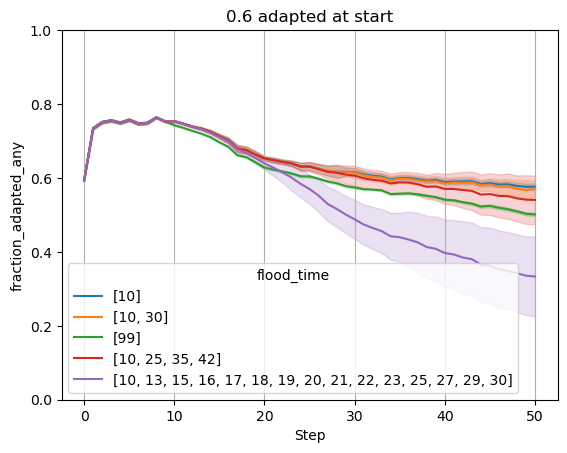

In [11]:
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') &
                                            (base_and_climate_runs['flood_depth_in_m'] == '[99, 0.5, 0.5, 0.5, 0.5]')], 
                                            x='Step', y='fraction_adapted_any', hue='flood_time', errorbar=('sd'))
# plt.axvline(10, 0, 1, color = 'grey', linestyle = '--')
plt.ylim(0, 1)
plt.title('0.6 adapted at start')
plt.grid(axis = 'x')

Text(0.5, 1.0, 'Base Case (no flooding)')

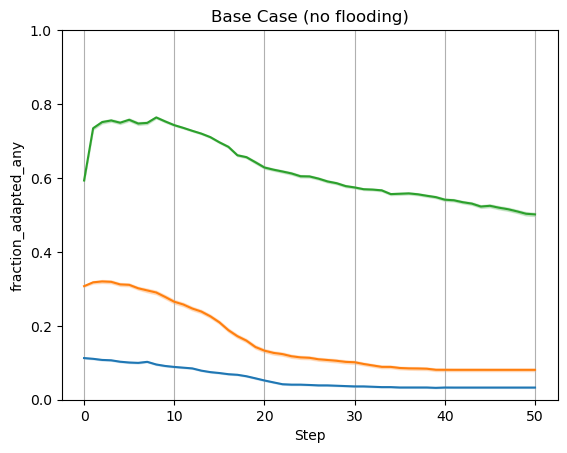

In [12]:
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='fraction_adapted_any', errorbar=('sd'))
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3')  & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='fraction_adapted_any', errorbar=('sd'))
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='fraction_adapted_any',  errorbar=('sd'))

plt.grid(axis = 'x')
plt.ylim(0, 1)
# plt.axvline(11, 0, 1, color = 'grey', linestyle = '--')
plt.title('Base Case (no flooding)')

- General downward trend 
- assumption: social dynamics not strong enough to sustain the adaptation efforts

('[10, 13, 15, 16, 17, 18, 19, 20, 21, 22, 23, 25, 27, 29, 30]', '[10, 25, 35, 42]', '[10, 30]', '[10]', '[99]')


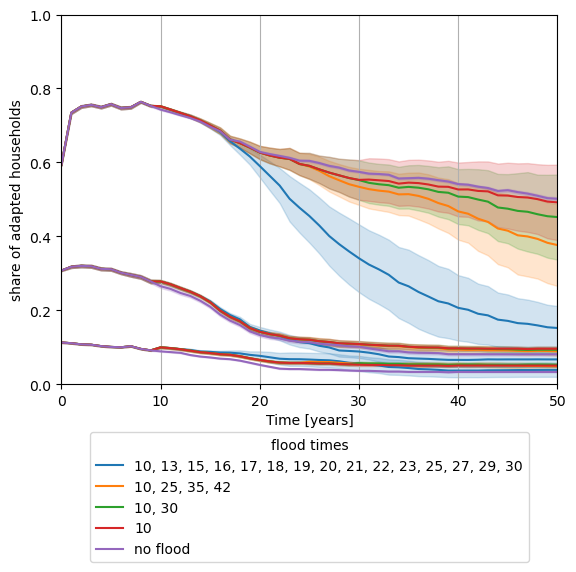

In [13]:
time_order = sorted(base_and_climate_runs['flood_time'].unique())
time_palette = dict(zip(time_order, sns.color_palette('tab10', n_colors=len(time_order))))

sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='fraction_adapted_any', hue='flood_time', hue_order=time_order, palette=time_palette, errorbar=('sd'))
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='fraction_adapted_any', hue='flood_time', hue_order=time_order, palette=time_palette, errorbar=('sd'), legend = False)
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='fraction_adapted_any', hue='flood_time', hue_order=time_order, palette=time_palette, errorbar=('sd'), legend = False)

plt.grid(axis = 'x')
plt.ylim(0, 1)
plt.xlim(0, 50)
plt.ylabel('share of adapted households')
plt.xlabel('Time [years]')
# plt.axvline(11, 0, 1, color='grey', linestyle='--')
handles, labels = plt.gca().get_legend_handles_labels()
filtered = [(h, l) for h, l in zip(handles, labels) if l != 'st.d.']
if filtered:
    handles, labels = zip(*filtered)
else:
    handles, labels = [], []
print(labels)
labels = ('10, 13, 15, 16, 17, 18, 19, 20, 21, 22, 23, 25, 27, 29, 30', '10, 25, 35, 42', '10, 30', '10', 'no flood')
plt.legend(handles=handles, labels=labels, title='flood times', loc='lower center', bbox_to_anchor=(0.5, -0.5))
plt.savefig('../reports/figures/climate_runs_flood_times.png', bbox_inches='tight', dpi=300)

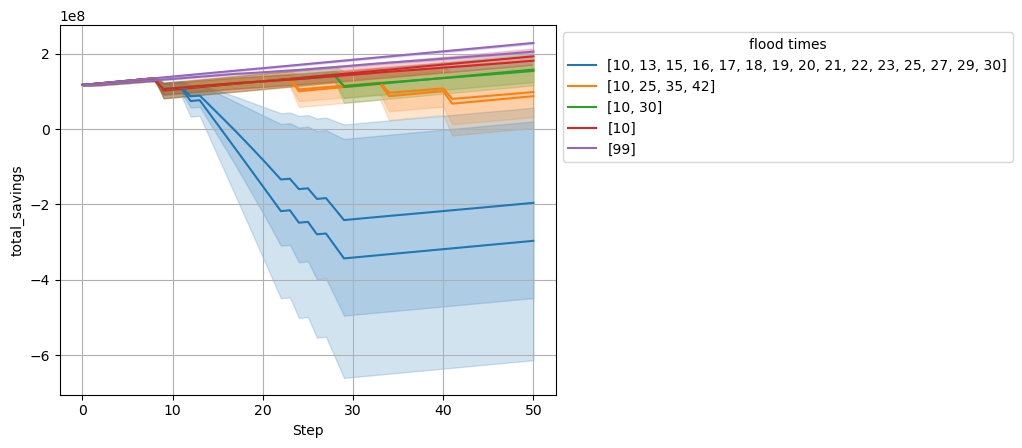

In [14]:
time_order = sorted(base_and_climate_runs['flood_time'].unique())
time_palette = dict(zip(time_order, sns.color_palette('tab10', n_colors=len(time_order))))

sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='total_savings', hue='flood_time', hue_order=time_order, palette=time_palette, errorbar=('sd'))
# sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='total_savings', hue='flood_time', hue_order=time_order, palette=time_palette, errorbar=('sd'), legend = False)
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='total_savings', hue='flood_time', hue_order=time_order, palette=time_palette, errorbar=('sd'), legend = False)

plt.grid()
# plt.axvline(11, 0, 1, color = 'grey', linestyle = '--')
plt.legend(title = 'flood times', loc ='upper left', bbox_to_anchor=(1, 1))

between 60 % adaptation at start and adaptation now nearly 100 million savings gap

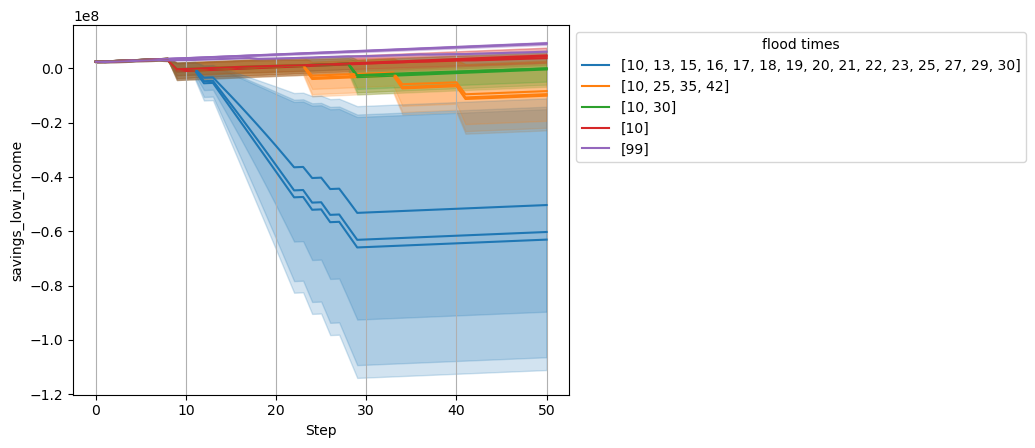

In [15]:
time_order = sorted(base_and_climate_runs['flood_time'].unique())
time_palette = dict(zip(time_order, sns.color_palette('tab10', n_colors=len(time_order))))

sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='savings_low_income', hue='flood_time', hue_order=time_order, palette=time_palette, errorbar=('sd'))
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='savings_low_income', hue='flood_time', hue_order=time_order, palette=time_palette, errorbar=('sd'), legend = False)
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='savings_low_income', hue='flood_time', hue_order=time_order, palette=time_palette, errorbar=('sd'), legend = False)

plt.grid(axis = 'x')
# plt.axvline(11, 0, 1, color = 'grey', linestyle = '--')
plt.legend(title = 'flood times', loc ='upper left', bbox_to_anchor=(1, 1))

- It matters a bit how deep the flood is
    - very extreme cases (5 m) the flood frequency doesn't matter anymore
    - for ligher floods (0.5, 1 m) flood frequency makes a difference
- flood frequency impact also depends on initial starting share of adapted

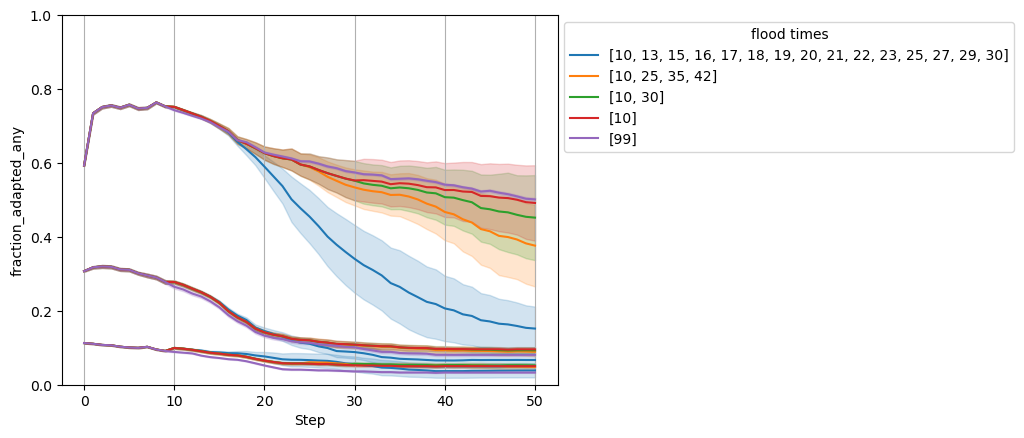

In [16]:
time_order = sorted(base_and_climate_runs['flood_time'].unique())
time_palette = dict(zip(time_order, sns.color_palette('tab10', n_colors=len(time_order))))

sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='fraction_adapted_any', hue='flood_time', hue_order=time_order, palette=time_palette, errorbar=('sd'))
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='fraction_adapted_any', hue='flood_time', hue_order=time_order, palette=time_palette, errorbar=('sd'), legend = False)
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='fraction_adapted_any', hue='flood_time', hue_order=time_order, palette=time_palette, errorbar=('sd'), legend = False)

plt.ylim(0, 1)
plt.grid(axis = 'x')
# plt.axvline(11, 0, 1, color = 'grey', linestyle = '--')
plt.legend(title = 'flood times', loc ='upper left', bbox_to_anchor=(1, 1))

('[99, 0.5, 0.5, 0.5, 0.5]', '[99, 1, 1, 1, 1]', '[99, 2, 2, 2, 2]', '[99, 3, 3, 3, 3]', '[99, 4, 4, 4, 4]', '[99, 5, 5, 5, 5]')


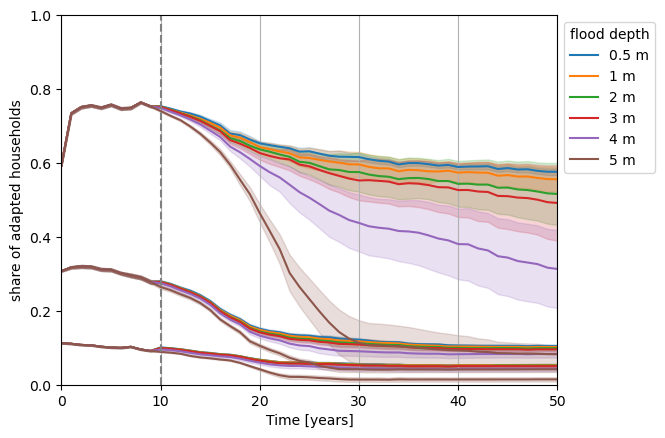

In [17]:
depth_order = sorted(base_and_climate_runs['flood_depth_in_m'].unique())
depth_palette = dict(zip(depth_order, sns.color_palette('tab10', n_colors=len(depth_order))))

sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_time'] == '[10]')], x='Step', y='fraction_adapted_any', hue='flood_depth_in_m', hue_order=depth_order, palette=depth_palette, errorbar=('sd'))
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3') & (base_and_climate_runs['flood_time'] == '[10]')], x='Step', y='fraction_adapted_any', hue='flood_depth_in_m', hue_order=depth_order, palette=depth_palette, errorbar=('sd'), legend = False)
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_time'] == '[10]')], x='Step', y='fraction_adapted_any', hue='flood_depth_in_m', hue_order=depth_order, palette=depth_palette, errorbar=('sd'), legend = False)

plt.ylim(0, 1)
plt.xlim(0, 50)
plt.grid(axis = 'x')
plt.axvline(10, 0, 1, color = 'grey', linestyle = '--')

plt.ylabel('share of adapted households')
plt.xlabel('Time [years]')

handles, labels = plt.gca().get_legend_handles_labels()
filtered = [(h, l) for h, l in zip(handles, labels) if l != 'st.d.']
if filtered:
    handles, labels = zip(*filtered)
else:
    handles, labels = [], []
print(labels)
labels = ('0.5 m', '1 m', '2 m', '3 m', '4 m', '5 m')
plt.legend(handles=handles, labels=labels, title='flood depth', loc='upper left', bbox_to_anchor=(1, 1))
plt.savefig('../reports/figures/climate_runs_flood_depth.png', bbox_inches='tight', dpi=300)

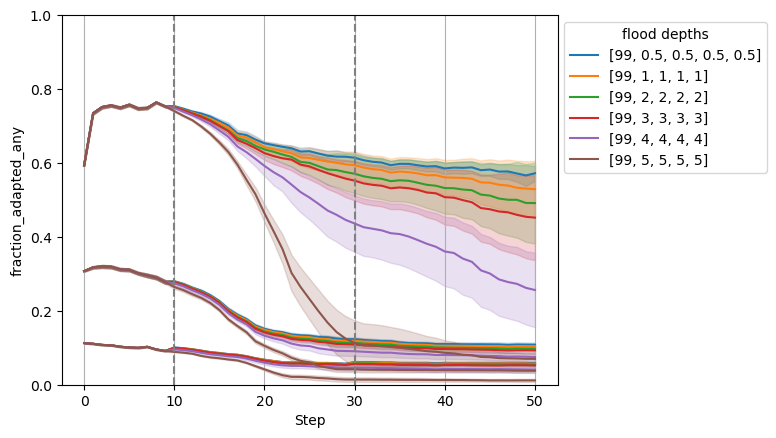

In [18]:
depth_order = sorted(base_and_climate_runs['flood_depth_in_m'].unique())
depth_palette = dict(zip(depth_order, sns.color_palette('tab10', n_colors=len(depth_order))))

sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_time'] == '[10, 30]')], x='Step', y='fraction_adapted_any', hue='flood_depth_in_m', hue_order=depth_order, palette=depth_palette, errorbar=('sd'))
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3') & (base_and_climate_runs['flood_time'] == '[10, 30]')], x='Step', y='fraction_adapted_any', hue='flood_depth_in_m', hue_order=depth_order, palette=depth_palette, errorbar=('sd'), legend = False)
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_time'] == '[10, 30]')], x='Step', y='fraction_adapted_any', hue='flood_depth_in_m', hue_order=depth_order, palette=depth_palette, errorbar=('sd'), legend = False)

plt.grid(axis = 'x')
plt.ylim(0, 1)
plt.axvline(10, 0, 1, color = 'grey', linestyle = '--')
plt.axvline(30, 0, 1, color = 'grey', linestyle = '--')
plt.legend(title = 'flood depths', loc ='upper left', bbox_to_anchor=(1, 1))

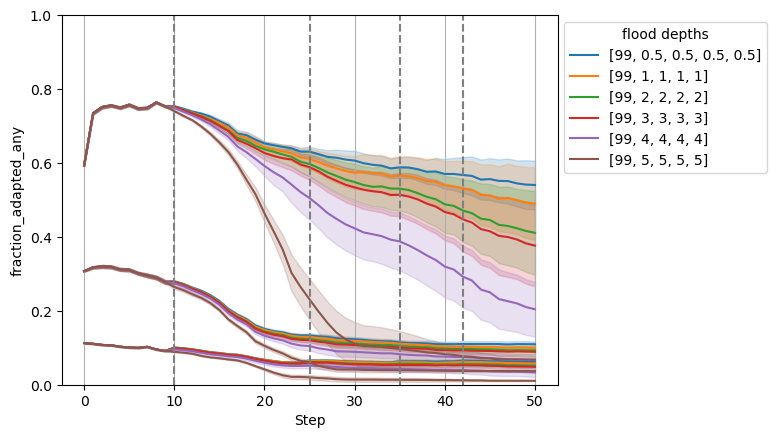

In [19]:
depth_order = sorted(base_and_climate_runs['flood_depth_in_m'].unique())
depth_palette = dict(zip(depth_order, sns.color_palette('tab10', n_colors=len(depth_order))))

sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_time'] == '[10, 25, 35, 42]')], x='Step', y='fraction_adapted_any', hue='flood_depth_in_m', hue_order=depth_order, palette=depth_palette, errorbar=('sd'))
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3') & (base_and_climate_runs['flood_time'] == '[10, 25, 35, 42]')], x='Step', y='fraction_adapted_any', hue='flood_depth_in_m', hue_order=depth_order, palette=depth_palette, errorbar=('sd'), legend = False)
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_time'] == '[10, 25, 35, 42]')], x='Step', y='fraction_adapted_any', hue='flood_depth_in_m', hue_order=depth_order, palette=depth_palette, errorbar=('sd'), legend = False)

plt.grid(axis = 'x')
plt.ylim(0, 1)
plt.axvline(10, 0, 1, color = 'grey', linestyle = '--')
plt.axvline(25, 0, 1, color = 'grey', linestyle = '--')
plt.axvline(35, 0, 1, color = 'grey', linestyle = '--')
plt.axvline(42, 0, 1, color = 'grey', linestyle = '--')
plt.legend(title = 'flood depths', loc ='upper left', bbox_to_anchor=(1, 1))

- it's mainly the first flood severity that determines the ability to recover
- later flood doesn't change the picture that much
